# Lineární klasifikace obrázků CIFAR10

Úkolem cvičení je naprogramovat lineární klasifikátor, který bude rozpoznávat objekty z datasetu CIFAR-10.
Vstupem je RGB obrázek o rozměrech 32$\times$32 pixelů a úkolem říci, který z 10 možných objektů (tříd) je na něm zachycen. Možnosti jsou tyto: letadlo, automobil, pták, kočka, jelen, pes, žába, kůň, loď, náklaďák.

**Model**
- Vstup: $x$, rozměr $N \times D$, kde $N$ je počet obrázků a $D$ počet číselných hodnot v jednom obrázku
  - Každý řádek je jeden obrázek reprezentovaný jako vektor, čísla v rozmezí 0-1.
- Parametr váhy (weights): $W$, rozměr $D \times C$
- Parametr bias: $b$, rozměr $C$
- Predikované skóre (logity): $s = xW + b$, rozměr $N \times C$
  - Pro každý obrázek predikce $C$ hodnot
- Predikovaná třída: $z = \arg\max_c s$, rozměr $N$
  - Pro každý obrázek vybereme třídu s nejvyšším skóre.

**Optimalizace**
- Kritérium křížová entropie: $L = \sum_c{p_c \cdot \log q_c}$
- Metoda Stochastic Gradient Descent (SGD)
  - $W := W - \gamma \frac{dL}{dW}$
  - $b := b - \gamma \frac{dL}{dW}$
  - Hyperparametr $\gamma$ značí rychlost učení (learning rate)

In [5]:
%load_ext autoreload
%autoreload 2

In [6]:
import sys
sys.path.append('..')  # import tests
from typing import Callable

import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision

import ans
from tests import test_linear_classification

In [7]:
torch.set_printoptions(profile='short')

# Načtení dat

Balík torchvision podporuje některé znamé datasety, mezi něž patří i CIFAR-10. Nemusíme tedy data stahovat z internetu manuálně, torchvision za nás vše obstará automaticky. Data uložíme do adresáře `./data`. Všimněme si flagu `train=True`, který říká, že se má načíst trénovací množina datasetu CIFAR-10 (soubory `data_batch_*`).

In [8]:
train_dataset = torchvision.datasets.CIFAR10(root='../data', train=True, download=False)
train_dataset

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: ../data
    Split: Train

Validovat budeme na zbylých 10000 obrázcích. Získáme je nastavením `train=False`.

In [9]:
val_dataset = torchvision.datasets.CIFAR10(root='../data', train=False, download=False)
val_dataset

Dataset CIFAR10
    Number of datapoints: 10000
    Root location: ../data
    Split: Test

Seznam tříd je uložen v atributu `.classes`.

In [10]:
train_dataset.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

Objekt třídy `torchvision.datasets.cifar.CIFAR10` se chová podobně jako pythonovský `list` s tím, že každý jeho prvek je dvojice (obrázek, třída).

In [11]:
train_dataset[5]

(<PIL.Image.Image image mode=RGB size=32x32 at 0x15177634E50>, 1)

Jak vidíme, 6. prvek datasetu je *dvojice* (`tuple`) sestávající z obrázku a jeho indexu třídy (label, target).

- Obrázek je defaultně navrácen jako typ `Image` knihovny Pillow (Python Imaging Library, PIL).

- Target je číslo typu `int` označující jednu ze tříd v atributu `.classes`.

Všechny obrázky CIFAR-10 datasetu jsou uloženy v atributu `.data`, což je 4D `numpy.ndarray` typu `np.uint8`. První dimenze odpovídá jednotlivým obrázkům, další pak řádkům, sloupcům a kanálům (RGB).

In [12]:
type(train_dataset.data), train_dataset.data.shape, train_dataset.data.dtype, train_dataset.data.min(), train_dataset.data.max()

(numpy.ndarray, (50000, 32, 32, 3), dtype('uint8'), 0, 255)

Podobně všechny targety jsou uložny v `.targets`, což je `list` o délce počtu obrázků, přičemž každý target číslo typu `int` v rozmezí 0-9, kde 0 značí letadlo (airplane), 1 značí automobil (automobile) atd.

In [13]:
type(train_dataset.targets), len(train_dataset.targets), type(train_dataset.targets[0]), min(train_dataset.targets), max(train_dataset.targets)

(list, 50000, int, 0, 9)

Pro lepší představu si vykreslíme sloupec 10 obrázků pro každou z 10 tříd.

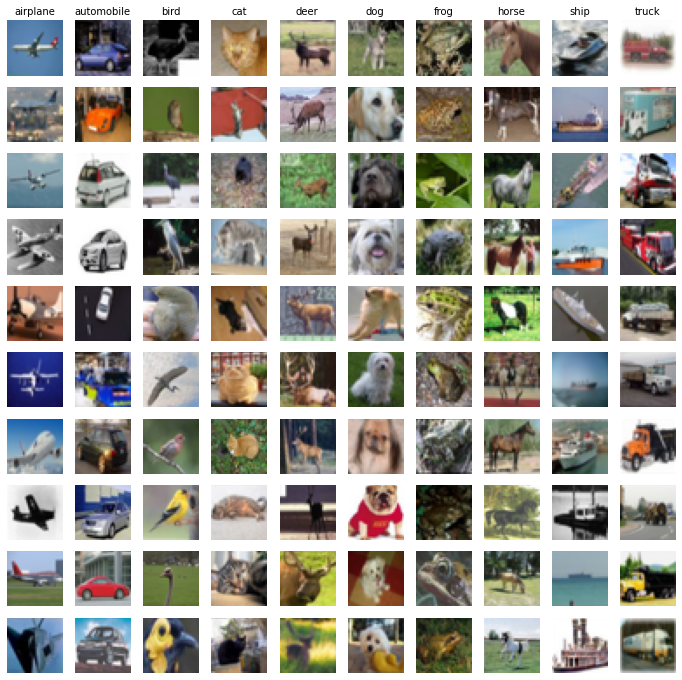

In [14]:
plt.figure(figsize=(12, 12))

for i, cls in enumerate(train_dataset.classes):
    # chceme pouze obrazky aktualni tridy a z nich nahodne vybereme 10
    cls_ids = [j for j, y in enumerate(train_dataset.targets) if y == i]
    draw_ids = np.random.choice(cls_ids, size=10)
    
    # pyplot podobne jako MATLAB nabizi funkci subplot pro vykresleni vice grafu do jednoho okna
    for j, k in enumerate(draw_ids):
        # vykresli 10x10 obrazku, poradi je po radcich, ovsem my budeme vykreslovat po sloupcich,
        # tj. kazdy sloupec bude obsahovat 10 prikladu jedne ze trid
        plt.subplot(10, 10, j * 10 + i + 1)
        
        # vyresli obrazek
        plt.imshow(train_dataset.data[k])
        
        # nevykresluj popisky os
        plt.axis('off')
        
        # v prvnim radku pridame nazev grafu (obrazku)
        if j == 0:
            plt.title(cls, fontsize=10)
plt.show()

# Načítání dat po dávkách

Prvním úkolem bude implementovat načítání dat po dávkách, na kterých se bude klasifikátor učit. Funkcionalita je implementovaná třídou `ans.data.BatchLoader` a nachází se v souboru `ans/data.py`. Třída implementuje metodu `__iter__` a je tedy možné ji použít jako zdroj např. pro `for` cyklus následujícím způsobem:
``` python
train_loader = ans.data.BatchLoader(
    torch.tensor(train_dataset.data),  # input images, shape (50000, 32, 32, 3)
    torch.tensor(train_dataset.targets),  # targets, shape (50000,)
    batch_size=100,
    shuffle=True  # return the data in random order
)
for inputs, targets in train_loader:
    # inputs ... shape (100, 32, 32, 3)
    # targets ... shape (100,)
    ...
```
**Úkol: implementujte metodu `__iter__` třídy `ans.data.BatchLoader`.**

Implementaci lze zkontrolovat připravenými unit testy.

In [15]:
test_linear_classification.TestBatchLoader.eval()

test_batch_size_even (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_batch_size_uneven (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_defaults (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok
test_output_tuple_supervised (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_output_tuple_unsupervised (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_shuffle (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.061s

OK


<unittest.runner.TextTestResult run=6 errors=0 failures=0>

In [16]:
train_loader = ans.data.BatchLoader(
    torch.tensor(train_dataset.data),
    torch.tensor(train_dataset.targets),
    batch_size=5,
    shuffle=True
)
train_loader

BatchLoader:
    num_batches: 10000
    batch_shape: (5, 32, 32, 3)

In [17]:
inputs, targets = next(iter(train_loader))
print(type(inputs), inputs.shape, inputs.dtype, inputs.min(), inputs.max())
print(type(targets), targets.shape, targets.dtype, targets.min(), targets.max())

<class 'torch.Tensor'> torch.Size([5, 32, 32, 3]) torch.uint8 tensor(0, dtype=torch.uint8) tensor(255, dtype=torch.uint8)
<class 'torch.Tensor'> torch.Size([5]) torch.int64 tensor(0) tensor(9)


In [18]:
val_loader = ans.data.BatchLoader(
    torch.tensor(val_dataset.data),
    torch.tensor(val_dataset.targets),
    batch_size=5,
    shuffle=False
)
val_loader

BatchLoader:
    num_batches: 2000
    batch_shape: (5, 32, 32, 3)

# Preprocessing

Data jsou celočiselného typu `torch.uint8`, což jsou čísla v rozmezí 0-255. Pro lepší numerické vlastnosti data převedeme do rozsahu 0-1 a datového typu `torch.float32`, který je pro PyTorch výchozí. Operaci provedeme jednoduchým vydělením max. hodnotou 255. Zároveň obrázky přetvarujeme do vektoru, takže výstup bude mít rozměr (batch_size, počet_pixelů). Celé předzpracování bude implementovat funkce `preprocess`, kterou budeme volat pro každou dávku po jejím načtení z `BatchLoader`u. Normalizovat budeme pouze obrázky, s targety nic dělat nebudeme.

**Úkol: implementuje funkci `preprocess`.**

In [19]:
def preprocess(inputs: torch.Tensor) -> torch.Tensor:
    """
    Args:
        inputs: n-dimensional tensor with first dimension of size num_inputs
    Returns:
        outputs: 2-dimensional tensor (num_inputs, num_features), dtype float32
    """
    
    ########################################
    outputs = torch.reshape(inputs,[inputs.shape[0], -1]) / 255
    
    ########################################
    
    return outputs

In [20]:
test_linear_classification.TestPreprocess.eval(preprocess_fn=preprocess)

test_preprocess (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 1 test in 0.012s

OK


<unittest.runner.TextTestResult run=1 errors=0 failures=0>

In [21]:
inputs_prep = preprocess(inputs)
inputs_prep

tensor([[0.71, 0.87,  ..., 0.74, 0.73],
        [0.56, 0.62,  ..., 0.28, 0.12],
        ...,
        [1.00, 1.00,  ..., 1.00, 1.00],
        [0.90, 0.91,  ..., 0.58, 0.54]])

# Inicializace

Váhovou matici $W$ klasifikátoru inicializujeme na náhodné hodnoty s normálním rozdělením a malou standardní odchylkou. Bias inicializujeme vektor nul s odpovídajícím rozměrem. Inicializaci bude provádět funkce `init_params`, která převezme rozměry a požadovanou odchylku (parametr `multiplier`) a vrátí dvojici (weight, bias).

Pozn.: nezapomínejme, že obrázky jsou uloženy *po řádcích* a náš model má podobu $s = xW + b$. Od toho se odvíjejí rozměry $W$ a $b$.

**Úkol: implementuje funkci `init_params`.**

In [22]:
def init_params(input_dim: int, output_dim: int, multiplier: float = 1e-2) -> tuple[torch.Tensor, torch.Tensor]:
    """
    Args:
        input_dim: size of one input
        output_dim: size of one output
        multiplier: standard deviation of weight
    Returns:
        weight, bias
    """
    
    ########################################
    weight = torch.randn([input_dim,output_dim]) * multiplier
    #weight = torch.empty(input_dim,output_dim).normal_(mean=0,std=multiplier)
    bias = torch.zeros(output_dim)
    

    ########################################
    
    return weight, bias

In [23]:
test_linear_classification.TestInit.eval(init_params_fn=init_params)

test_init_params (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 1 test in 0.009s

OK


<unittest.runner.TextTestResult run=1 errors=0 failures=0>

In [24]:
weight, bias = init_params(3072,10)
weight, bias

(tensor([[-8.85e-04,  5.24e-03, -6.66e-03,  8.50e-03, -1.35e-02],
         [-1.70e-02,  5.67e-03,  7.94e-03, -1.93e-03,  1.12e-03],
         [ 6.41e-03,  4.41e-03, -2.16e-03, -7.43e-03,  5.63e-03],
         [ 2.60e-03, -1.74e-03,  2.30e-02, -1.47e-02, -1.59e-02],
         [ 1.20e-02,  8.45e-04, -1.20e-02, -4.79e-05, -5.18e-03]]),
 tensor([0., 0., 0., 0., 0.]))

# Výpočet lineárních skóre (logitů)

Nyní vypočteme lineární skóre (logity) jako
$$s_n = x_nW + b$$
kde
- $s_n$ je vektor skóre pro $n$-tý vzorek (obrázek) $x_n$ a každou z $C$ tříd
- $x_n$ je $n$-tý vzorek (obrázek) v dávce reprezentovaný jako (řádkový) vektor
- $W$ je matice vah klasifikátoru
- $b$ je bias klasifikátoru

Výpočet bude zajišťovat funkce `calc_linear_scores`

**Úkol: implementuje funkci `calc_linear_scores`.**

In [25]:
def calc_linear_scores(inputs: torch.Tensor, weight: torch.Tensor, bias: torch.Tensor) -> torch.Tensor:
    """
    Args:
        inputs: shape (num_samples, num_features)
        weight: shape (num_features, num_classes)
        bias: shape (num_classes,)
    Returns:
        scores: shape (num_samples, num_classes)
    """
    ########################################
    scores = (inputs @ weight) + bias
    
    
    ########################################
    
    return scores

In [26]:
test_linear_classification.TestCalcLinearScores.eval(calc_linear_scores_fn=calc_linear_scores)

test_calc_linear_scores (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok
test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.014s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

In [27]:
logits = calc_linear_scores(inputs_prep, weight, bias)
logits

tensor([[ 0.00,  0.01,  ..., -0.01, -0.03],
        [ 0.00,  0.01,  ..., -0.01, -0.03],
        ...,
        [ 0.01,  0.01,  ..., -0.01, -0.03],
        [ 0.01,  0.00,  ..., -0.01, -0.03]])

# Kritérium: softmax cross entropy loss

Výstupní pravděpodobnost $c$-té třídy $q_{nc}$ predikovaná klasifikátorem pro $x_n$ získáme aplikací funkce softmax na skóre $s$
$$q_{nc} = \frac{\exp{s_{nc}}}{\sum_{i=1}^{C}{\exp{s_{ni}}}}, c=1,\ldots,C$$
kde
- $s_{nj}$ je predikované skóre $n$-tého vzorku dávky třídy $j$

Klasifikátor budeme trénovat optimalizací křížové entropie mezi predikovanými $q_{nc}$ a skutečnými pravděpodobnostmi $p_{nc}$
$$L_n = \sum_c{p_{nc} \log q_{nc}}$$
kde
- $L_n$ je hodnota kritéria pro $n$-tý vzorek $x_n$ dávky $x$

Jelikož pro každý obrázek známe, který objekt je na něm zachycen, skutečné diskrétní rozdělení pravděpodobnosti $p_n=[p_{n1},\ldots,p_{nC}]$ má pouze jednu hodnotu $p_{nc}=1$ a to správnou třídu $c=y_n$; ostatní $p_{nc}=0, c \ne y_n$ jsou nulové. Jde tedy o tzv. one hot vektor. Sloučením softmaxu a odstranění nulových členů ve vztahu pro výpočet entropie získáme
$$L_n = \log q_{ny_n} = \log\frac{\exp{s_{ny_n}}}{\sum_{c=1}^{C}{\exp{s_{nc}}}} = -s_{ny_n} + \log\sum_c\exp s_{nc}$$
Loss tedy můžeme počítat přímo z lineárních skóre (logitů), což s sebou zároveň přináší výhodu modularity, protože později takto bude možné kritérium jednoduše vyměnit např. za hinge loss a namísto logistické regrese tak trénovat klasifikátor SVM. Kritérium bude počítat funkce `softmax_cross_entropy`.

**Úkol: implementujte funkci `softmax_cross_entropy`**

In [28]:
def softmax_cross_entropy(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """
    Args:
        scores: output linear scores (logits before softmax); shape (num_samples, num_classes)
        targets: vector of class indicies (integers); shape (num_samples,)
    Returns:
        loss: averare cross entropy on the batch; tensor containing single number (scalar), e.g. "tensor(2.23)"
    """

    ln = - scores[torch.arange(scores.shape[0]), targets] + torch.log(torch.sum(torch.exp(scores),dim = 1))
    loss = torch.mean(ln)

    
    return loss

In [29]:
test_linear_classification.TestSoftmaxCrossEntropy.eval(softmax_cross_entropy_fn=softmax_cross_entropy)

test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_softmax_cross_entropy (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 2 tests in 0.023s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

In [30]:
loss = softmax_cross_entropy(logits.T, targets)
loss

tensor(8.03)

    # Úspěšnost: accuracy

Kromě lossu budeme pro lepší orientaci měřit i přesnost (accuracy), byť tuto veličinu nebudeme přímo optimalizovat.

**Úkol: implementujte funkci `accuracy`**

In [31]:
def accuracy(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """
    Args:
        scores: output linear scores (logits before softmax); shape (num_samples, num_classes)
        targets: vector of class indicies (integers); shape (num_samples,)
    Returns:
        acc: averare accuracy on the batch; tensor containing single number (scalar), e.g. "tensor(0.364)"
    """
    
    ########################################
    # TODO: implement
    predicted = torch.argmax(scores, dim=1)
    acc = torch.sum(torch.where(predicted == targets,1 , 0)) / targets.shape[0]
    # ENDTODO
    ########################################
    
    return acc

In [32]:
test_linear_classification.TestAccuracy.eval(accuracy_fn=accuracy)

test_cross_entropy (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok
test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.012s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

# Gradient na parametry

Optimalizace lossu $L$ bude probíhat stochastickou metodou nejvějtšího spádu (Stochastic Gradient Descent, SGD). K tomu potřebujeme znát gradient na jednotlivé parametry, na kterých $L$ závisí:

Gradient na $c$-tý řádek matice $W$:
$$\frac{\partial L_n}{\partial w_c} = \frac{1}{N}(q_{nc} - p_{nc})x_n$$
kde
- $x_n$ $n$-tý vzorek dávky
- $q_{nc}$ je pravděpodobnost $c$-té třídy predikovaná pro $x_n$
- $p_{nc}$ je cílová požadovaná pravděpodobnost pro $x_n$
- $N$ je počet vzorků $x_n$ v dávce $x$.

Gradient na $c$-tý prvek biasu:
$$\frac{\partial L}{\partial b_c} = \frac{1}{N}(q_{nc} - p_{nc})$$

Oba gradienty bude vracet funkce `softmax_cross_entropy_gradients`, přičemž vstupem jí budou potřebné proměnné, tj. $x$, $q$ a $p$.

**Úkol: implementuje funkci `softmax_cross_entropy_gradients`**

In [81]:
def softmax_cross_entropy_gradients(inputs: torch.Tensor,logits: torch.Tensor,targets: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    ########################################

    sm = torch.exp(logits) / torch.sum(torch.exp(logits),dim = 1)[:,None]
    sm[torch.arange(logits.shape[0]),targets] -= 1
    sm /= logits.shape[0]

    dweight =  inputs.T @ sm
    dbias = torch.sum(sm,dim = 0)


    ########################################
    
    return dweight, dbias

In [83]:
test_linear_classification.TestSoftmaxCrossEntropyGradients.eval(softmax_cross_entropy_gradients_fn=softmax_cross_entropy_gradients)

test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_softmax_cross_entropy_gradients (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 2 tests in 0.008s

OK


tensor([ 0.35, -0.36,  0.01]) tensor([[-0.23,  0.21,  0.03],
        [ 0.31, -0.42,  0.10],
        [ 0.07, -0.06, -0.01],
        [-0.38,  0.10,  0.28]])


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

In [84]:
dweight, dbias = softmax_cross_entropy_gradients(inputs_prep, logits, targets)
dweight, dbias

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [3072], [5]

# Update parametrů

Update bude probíhat metodou největšího spádu (Gradient Descent), tj. od aktuáního odhadu parametrů $\theta$ odečteme gradient $\frac{dL}{\theta}$ přeškálovaný krokem $\gamma$:

$\theta := \theta - \gamma \frac{dL}{\theta}$

Update implementujeme jako funkci, která převezme parametr, gradient na něj a krok učení $\gamma$ a parametr updatuje. Nebude přitom bytečně vytvářet jeho kopii, vše proběhne modifikací původního tensoru, anglicky tzv. inplace.

**Úkol: implementuje funkci `update_param_inplace`**

In [85]:
def update_param_inplace(param: torch.Tensor, dparam: torch.Tensor, learning_rate: float) -> None:
    ########################################
    # TODO: implement
    
    param +=  -learning_rate * dparam
    
    # ENDTODO
    ########################################

In [86]:
test_linear_classification.TestUpdateParamInplace.eval(update_param_inplace_fn=update_param_inplace)

test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_update_param_inplace (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 2 tests in 0.009s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

In [87]:
weight, bias

(tensor([[-8.85e-04,  5.24e-03, -6.66e-03,  8.50e-03, -1.35e-02],
         [-1.70e-02,  5.67e-03,  7.94e-03, -1.93e-03,  1.12e-03],
         [ 6.41e-03,  4.41e-03, -2.16e-03, -7.43e-03,  5.63e-03],
         [ 2.60e-03, -1.74e-03,  2.30e-02, -1.47e-02, -1.59e-02],
         [ 1.20e-02,  8.45e-04, -1.20e-02, -4.79e-05, -5.18e-03]]),
 tensor([0., 0., 0., 0., 0.]))

In [88]:
update_param_inplace(weight, dweight, 0.1)
update_param_inplace(bias, dbias, 0.1)

NameError: name 'dweight' is not defined

In [ ]:
weight, bias

# Spojení všech kroků dohromady: funkce `train_step` a `val_step`

Nyní spojíme všechny kroky do jedné funkce `train_step_softmax`, která převezme dávku vzorků, aktuální parametry klasifikátoru a hyperparametr krok učení a provede jeden krok směrem k mnimializaci křížové entropie na dávce. Funkce vrátí hodnotu lossu a přesnosti (accuracy) dosaženou na dávce.

**Úkol: implementuje funkci `train_step_softmax`**

In [89]:
def train_step_softmax(
    inputs: torch.Tensor,
    targets: torch.Tensor,
    weight: torch.Tensor,
    bias: torch.Tensor,
    learning_rate: float = 1e-3
) -> tuple[float, float]:
    ########################################
    # TODO: implement
    inputs = preprocess(inputs)
    logits = calc_linear_scores(inputs,weight,bias)
    dw, db = softmax_cross_entropy_gradients(inputs,logits,targets)
    update_param_inplace(weight,dw , learning_rate)
    update_param_inplace(bias, db, learning_rate)
    loss = softmax_cross_entropy(logits,targets)
    acc = accuracy(logits,targets)
    
    # ENDTODO
    ########################################
    
    return loss.item(), acc.item()

In [90]:
test_linear_classification.TestTrainStepSoftmax.eval(train_step_softmax_fn=train_step_softmax)

test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_train_step_softmax (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 2 tests in 0.009s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

**Úkol: implementuje funkci `val_step`**

In [91]:
def val_step(
    inputs: torch.Tensor,
    targets: torch.Tensor,
    weight: torch.Tensor,
    bias: torch.Tensor,
    loss_fn: Callable[[torch.Tensor, torch.Tensor], tuple[float, float]]  # e.g. softmax_cross_entropy
) -> tuple[float, float]:
    ########################################

    inputs = preprocess(inputs)
    logits = calc_linear_scores(inputs,weight,bias)
    acc = accuracy(logits,targets)
    loss = loss_fn(logits,targets)

    ########################################
    return loss.item(), acc.item()

In [92]:
test_linear_classification.TestValStep.eval(val_step_fn=val_step, loss_fn=softmax_cross_entropy)

test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_val_step (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok

----------------------------------------------------------------------
Ran 2 tests in 0.009s

OK


<unittest.runner.TextTestResult run=2 errors=0 failures=0>

In [93]:
def validate(
    loader: ans.data.BatchLoader,
    weight: torch.Tensor,
    bias: torch.Tensor,
    loss_fn: Callable[[torch.Tensor, torch.Tensor], tuple[float, float]]  # e.g. softmax_cross_entropy
) -> tuple[float, float]:
    total_loss = 0.
    total_acc = 0.
    for inputs, targets in loader:
        loss, acc = val_step(inputs, targets, weight, bias, loss_fn)
        total_loss += loss
        total_acc += acc
    return total_loss / len(loader), total_acc / len(loader)

In [100]:
ans.utils.seed_everything(0)

# hyperparameters
num_epochs = 50
learning_rate =0.001

# data loaders
train_loader = ans.data.BatchLoader(
    torch.tensor(train_dataset.data),
    torch.tensor(train_dataset.targets),
    batch_size=32,
    shuffle=True
)
val_loader = ans.data.BatchLoader(
    torch.tensor(val_dataset.data),
    torch.tensor(val_dataset.targets),
    batch_size=32,
    shuffle=False
)

# init parameters
weight, bias = init_params(3072,10)

# validate once before training
train_loss, train_acc = validate(train_loader, weight, bias, softmax_cross_entropy)
val_loss, val_acc = validate(val_loader, weight, bias, softmax_cross_entropy)
print(f"after init: train_loss={train_loss:.5f}, train_acc={train_acc:.3f}, val_loss={val_loss:.5f}, val_acc={val_acc:.3f}")

# optimize
for epoch in range(num_epochs):
    # train loop
    for inputs, targets in train_loader:
        loss, acc = train_step_softmax(inputs, targets, weight, bias, learning_rate=learning_rate)
        train_loss = 0.99 * train_loss + 0.01 * loss
        train_acc = 0.99 * train_acc + 0.01 * acc
    
    # validation loop
    # train_loss, train_acc = validate(train_loader, weight, bias, softmax_cross_entropy)
    val_loss, val_acc = validate(val_loader, weight, bias, softmax_cross_entropy)
    
    # print
    print(f"epoch {epoch + 1}: train_loss={train_loss:.5f}, train_acc={train_acc:.3f}, val_loss={val_loss:.5f}, val_acc={val_acc:.3f}")

after init: train_loss=2.36420, train_acc=0.106, val_loss=2.36536, val_acc=0.105
epoch 1: train_loss=1.96542, train_acc=0.316, val_loss=1.96694, val_acc=0.330
epoch 2: train_loss=1.89849, train_acc=0.347, val_loss=1.90376, val_acc=0.347
epoch 3: train_loss=1.87105, train_acc=0.359, val_loss=1.86740, val_acc=0.356
epoch 4: train_loss=1.83838, train_acc=0.367, val_loss=1.84642, val_acc=0.370
epoch 5: train_loss=1.82940, train_acc=0.368, val_loss=1.83191, val_acc=0.371
epoch 6: train_loss=1.81969, train_acc=0.378, val_loss=1.81974, val_acc=0.371
epoch 7: train_loss=1.81200, train_acc=0.386, val_loss=1.81378, val_acc=0.374
epoch 8: train_loss=1.78874, train_acc=0.393, val_loss=1.80504, val_acc=0.375
epoch 9: train_loss=1.78479, train_acc=0.398, val_loss=1.80157, val_acc=0.377
epoch 10: train_loss=1.78334, train_acc=0.390, val_loss=1.79224, val_acc=0.381
epoch 11: train_loss=1.78195, train_acc=0.386, val_loss=1.79075, val_acc=0.377
epoch 12: train_loss=1.78273, train_acc=0.393, val_loss=1.7

# Support Vector Machine (SVM)

SVM je softmaxu velmi podobné. Z pohledu neuronových sítí se liší pouze způsobem výpočtu lossu - místo cross entropy použijeme hinge loss:
$$L_n = \sum_{c\ne y_n}\max(0, 1 + s_{nc} - s_{ny})$$
kde:
- $y_n$ je správný index třídy na vzorku (obrázku) $x_n$
- $s_{ni}$ je skóre (logity) predikované lineárním klasifikátorem pro $n$-tý obrázek a $i$-tou třídu.

Gradient na váhy pak je
$$\frac{\partial L_n}{\partial w_{y_n}} = -\sum_{c\ne y_n}\boldsymbol{1}(1 + s_{nc} - s_{ny} > 0)x_n$$
$$\frac{\partial L_n}{\partial w_{c\ne y_n}} = \boldsymbol{1}(1 + s_c - s_y > 0)x_n$$
a pro biasy podobně, pouze bez násobení $x_n$ (na konci).

**Úkol: implementuje funkce `hinge_loss`, `hinge_loss_gradients` a `train_step_svm`**

In [558]:

def hinge_loss(scores: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    """
    Args:
        scores: output from linear classifier, i.e. the pre-softmax logits; shape (num_samples, num_classes)
        targets: vector of class indicies (integers); shape (num_samples,)
    Returns:
        loss: averare Weston-Watkins hinge loss on the batch; tensor containing single number (scalar), e.g. "tensor(2.374)"
    """
    
    ########################################

    body = 1 + scores - scores[torch.arange(scores.shape[0]), targets][:, None] #need to expand dim to broadcast substract
    body[torch.arange(body.shape[0]), targets] = 0 #set to zero where yn = c
    loss = torch.mean(torch.sum(torch.max(torch.tensor(0),torch.tensor(body)),dim = 1)) # sum row vectors to Ln (rows), mean final L

    ########################################
    
    return loss

In [559]:
test_linear_classification.TestHingeLoss.eval(hinge_loss_fn=hinge_loss)

test_hinge_loss (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\AppData\Local\Temp\ipykernel_298956\1314417050.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss = torch.mean(torch.sum(torch.max(torch.tensor(0),torch.tensor(body)),dim = 1)) # sum row vectors to Ln (rows), mean final L
C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py:35: FutureWarning: torch.testing.assert_allclose() is deprecated since 1.12 and will be removed in 1.14. Use torch.testing.assert_close() instead. For detailed upgrade instructions see https://github.com/pytorch/pytorch/issues/61844.
  warnings.warn(msg, FutureWarning)
ok
test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_no_loops (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok

-------------------------

<unittest.runner.TextTestResult run=3 errors=0 failures=0>

In [562]:


def hinge_loss_gradients(
    inputs: torch.Tensor,
    scores: torch.Tensor,
    targets: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    
    ########################################
    # TODO: implement
    body = 1 + scores - scores[torch.arange(scores.shape[0]), targets][:, None] #need to expand dim to broadcast substract
    body[torch.arange(body.shape[0]), targets] = 0 #set to zero where yn = c
    dbias = torch.tensor(body) # sum row vectors to Ln (rows), mean final L
    print(dbias)
    dweight = 0
    
    # ENDTODO
    ########################################
    
    return dweight, dbias

In [563]:
test_linear_classification.TestHingeLossGradients.eval(hinge_loss_gradients_fn=hinge_loss_gradients)

test_hinge_loss_gradients (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\AppData\Local\Temp\ipykernel_298956\18019944.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dbias = torch.tensor(body) # sum row vectors to Ln (rows), mean final L
FAIL

FAIL: test_hinge_loss_gradients (tests.ANSTestCase.eval.<locals>._TestCaseClass)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "E:\VS-TUL\5.semestr\ANS\tests\test_linear_classification.py", line 264, in test_hinge_loss_gradients
    torch.testing.assert_allclose(dweight, expected_dweight, rtol=1e-3, atol=1e-4)
  File "C:\Users\podav\anaconda3\envs\data_science\lib\site-packages\torch\testing\_deprecated.py", line 32, in inner_wrapper
    return_value = fn(*args, **kwargs)
  File "C:\Users\podav\anaconda3\e

tensor([[ 1.65,  1.62,  0.00],
        [ 0.00, -2.76, -4.12],
        [ 0.00, -4.28, -5.87],
        [ 3.58,  0.00,  0.20],
        [ 0.00,  1.79,  3.65],
        [ 0.83,  0.00,  1.27],
        [ 2.49,  0.54,  0.00],
        [ 0.00, -2.17, -4.50]])
tensor([ 0.25, -0.12, -0.12]) tensor([[-0.68, -0.36,  1.03],
        [-0.68,  0.34,  0.34],
        [ 0.52,  0.05, -0.57],
        [-0.71,  0.80, -0.09],
        [-0.09, -0.28,  0.37]])


<unittest.runner.TextTestResult run=1 errors=0 failures=1>

In [552]:
def train_step_svm(
    inputs: torch.Tensor,
    targets: torch.Tensor,
    weight: torch.Tensor,
    bias: torch.Tensor,
    learning_rate: float = 1e-3
) -> tuple[float, float]:
    ########################################
    # TODO: implement
    inputs = preprocess(inputs)
    logits = calc_linear_scores(inputs,weight,bias)
    loss = hinge_loss(logits,targets)

    dw, db = hinge_loss_gradients(inputs,logits,targets)
    update_param_inplace(weight,dw , learning_rate)
    update_param_inplace(bias, db, learning_rate)

    acc = accuracy(logits,targets)
    
    
    # ENDTODO
    ########################################
    
    return loss.item(), acc.item()

In [553]:
test_linear_classification.TestTrainStepSVM.eval(train_step_svm_fn=train_step_svm)

test_implementation (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... ok
test_train_step_svm (tests.ANSTestCase.eval.<locals>._TestCaseClass) ... C:\Users\podav\AppData\Local\Temp\ipykernel_298956\1314417050.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  loss = torch.mean(torch.sum(torch.max(torch.tensor(0),torch.tensor(body)),dim = 1)) # sum row vectors to Ln (rows), mean final L
ERROR

ERROR: test_train_step_svm (tests.ANSTestCase.eval.<locals>._TestCaseClass)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "E:\VS-TUL\5.semestr\ANS\tests\test_linear_classification.py", line 284, in test_train_step_svm
    loss, acc = self.params['train_step_svm_fn'](inputs, targets, weight, bias, learning_rate=learning_rate)
  File "C:\Users\podav\AppData\Local\Temp\ipykernel_29

<unittest.runner.TextTestResult run=2 errors=1 failures=0>

In [ ]:
ans.utils.seed_everything(0)

# hyperparameters
num_epochs = ...
learning_rate = ...

# data loaders
train_loader = ans.data.BatchLoader(
    torch.tensor(train_dataset.data),
    torch.tensor(train_dataset.targets),
    batch_size=...,
    shuffle=True
)
val_loader = ans.data.BatchLoader(
    torch.tensor(val_dataset.data),
    torch.tensor(val_dataset.targets),
    batch_size=...,
    shuffle=False
)

# init parameters
weight, bias = init_params(...)

# validate once before training
train_loss, train_acc = validate(train_loader, weight, bias, hinge_loss)
val_loss, val_acc = validate(val_loader, weight, bias, hinge_loss)
print(f"after init: train_loss={train_loss:.5f}, train_acc={train_acc:.3f}, val_loss={val_loss:.5f}, val_acc={val_acc:.3f}")

# optimize
for epoch in range(num_epochs):
    # train loop
    for inputs, targets in train_loader:
        loss, acc = train_step_svm(inputs, targets, weight, bias, learning_rate=learning_rate)
        train_loss = 0.99 * train_loss + 0.01 * loss
        train_acc = 0.99 * train_acc + 0.01 * acc
    
    # validation loop
    # train_loss, train_acc = validate(train_loader, weight, bias, hinge_loss)
    val_loss, val_acc = validate(val_loader, weight, bias, hinge_loss)
    
    # print
    print(f"epoch {epoch + 1}: train_loss={train_loss:.5f}, train_acc={train_acc:.3f}, val_loss={val_loss:.5f}, val_acc={val_acc:.3f}")